In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot styles
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)


In [3]:
df = pd.read_csv('deliveries.csv')

In [12]:
#basic structure
df.head()

,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN


In [10]:
df.describe()

,match_id,inning,over,ball,batsman_runs,extra_runs,total_runs,is_wicket
count,2.609200e+05,260920.000000,260920.000000,260920.000000,260920.000000,260920.000000,260920.000000,260920.000000
mean,9.070665e+05,1.483531,9.197677,3.624486,1.265001,0.067806,1.332807,0.049632
std,3.679913e+05,0.502643,5.683484,1.814920,1.639298,0.343265,1.626416,0.217184
min,3.359820e+05,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,5.483340e+05,1.000000,4.000000,2.000000,0.000000,0.000000,0.000000,0.000000
50%,9.809670e+05,1.000000,9.000000,4.000000,1.000000,0.000000,1.000000,0.000000
75%,1.254066e+06,2.000000,14.000000,5.000000,1.000000,0.000000,1.000000,0.000000
max,1.426312e+06,6.000000,19.000000,11.000000,6.000000,7.000000,7.000000,1.000000


In [13]:
df.columns

Index(['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball',
       'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs',
       'total_runs', 'extras_type', 'is_wicket', 'player_dismissed',
       'dismissal_kind', 'fielder'],
      dtype='object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260920 entries, 0 to 260919
Data columns (total 17 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   match_id          260920 non-null  int64 
 1   inning            260920 non-null  int64 
 2   batting_team      260920 non-null  object
 3   bowling_team      260920 non-null  object
 4   over              260920 non-null  int64 
 5   ball              260920 non-null  int64 
 6   batter            260920 non-null  object
 7   bowler            260920 non-null  object
 8   non_striker       260920 non-null  object
 9   batsman_runs      260920 non-null  int64 
 10  extra_runs        260920 non-null  int64 
 11  total_runs        260920 non-null  int64 
 12  extras_type       14125 non-null   object
 13  is_wicket         260920 non-null  int64 
 14  player_dismissed  12950 non-null   object
 15  dismissal_kind    12950 non-null   object
 16  fielder           9354 non-null    obj

In [14]:
df['match_id'].nunique()

1095

In [7]:
df.shape

(260920, 17)

In [18]:
# Count the number of null values in each column
print(df.isnull().sum())

match_id                 0
inning                   0
batting_team             0
bowling_team             0
over                     0
ball                     0
batter                   0
bowler                   0
non_striker              0
batsman_runs             0
extra_runs               0
total_runs               0
extras_type         246795
is_wicket                0
player_dismissed    247970
dismissal_kind      247970
fielder             251566
dtype: int64


In [20]:
# Display all unique team names from the 'batting_te' column
print("Unique Team Names:")
print(sorted(df['batting_team'].unique()))

Unique Team Names:
['Chennai Super Kings', 'Deccan Chargers', 'Delhi Capitals', 'Delhi Daredevils', 'Gujarat Lions', 'Gujarat Titans', 'Kings XI Punjab', 'Kochi Tuskers Kerala', 'Kolkata Knight Riders', 'Lucknow Super Giants', 'Mumbai Indians', 'Pune Warriors', 'Punjab Kings', 'Rajasthan Royals', 'Rising Pune Supergiant', 'Rising Pune Supergiants', 'Royal Challengers Bangalore', 'Royal Challengers Bengaluru', 'Sunrisers Hyderabad']


In [21]:
def get_phase(over):
    """Categorizes an over into Powerplay, Middle, or Death phase."""
    if over < 6:
        return 'Powerplay'
    elif over < 16:
        return 'Middle'
    else:
        return 'Death'

In [23]:
# Apply the function to the 'over' column to create the new 'phase' column
df['phase'] = df['over'].apply(get_phase)

print("'phase' column created successfully.")
# Display the 'over' and the new 'phase' columns for the first 10 rows
print(df[['over', 'phase']].head(10))

'phase' column created successfully.
   over      phase
0     0  Powerplay
1     0  Powerplay
2     0  Powerplay
3     0  Powerplay
4     0  Powerplay
5     0  Powerplay
6     0  Powerplay
7     1  Powerplay
8     1  Powerplay
9     1  Powerplay


In [29]:
# Create a dictionary to map old names to new names
team_name_mapping = {
    'Delhi Daredevils': 'Delhi Capitals',
    'Deccan Chargers': 'Sunrisers Hyderabad',
    'Kings XI Punjab': 'Punjab Kings',
    'Rising Pune Supergiant': 'Rising Pune Supergiants',
    'Royal Challengers Bangalore': 'Royal Challengers Bengaluru'
}

df['batting_team'] = df['batting_team'].replace(team_name_mapping)
df['bowling_team'] = df['bowling_team'].replace(team_name_mapping)

print("Team names have been standardized.")
# Display the unique team names again to confirm the changes
print("--- Standardized Unique Team Names ---")
print(sorted(df['batting_team'].unique()))

Team names have been standardized.
--- Standardized Unique Team Names ---
['Chennai Super Kings', 'Delhi Capitals', 'Gujarat Lions', 'Gujarat Titans', 'Kochi Tuskers Kerala', 'Kolkata Knight Riders', 'Lucknow Super Giants', 'Mumbai Indians', 'Pune Warriors', 'Punjab Kings', 'Rajasthan Royals', 'Rising Pune Supergiants', 'Royal Challengers Bengaluru', 'Sunrisers Hyderabad']


batter
V Kohli           8014
S Dhawan          6769
RG Sharma         6630
DA Warner         6567
SK Raina          5536
MS Dhoni          5243
AB de Villiers    5181
CH Gayle          4997
RV Uthappa        4954
KD Karthik        4843
KL Rahul          4689
AM Rahane         4642
F du Plessis      4571
SV Samson         4419
AT Rayudu         4348
G Gambhir         4217
SR Watson         3880
MK Pandey         3859
SA Yadav          3594
JC Buttler        3583
Name: batsman_runs, dtype: int64


C:\Users\amogh\AppData\Local\Temp\ipykernel_9500\2948619177.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_scorers.values, y=top_scorers.index, palette='viridis')


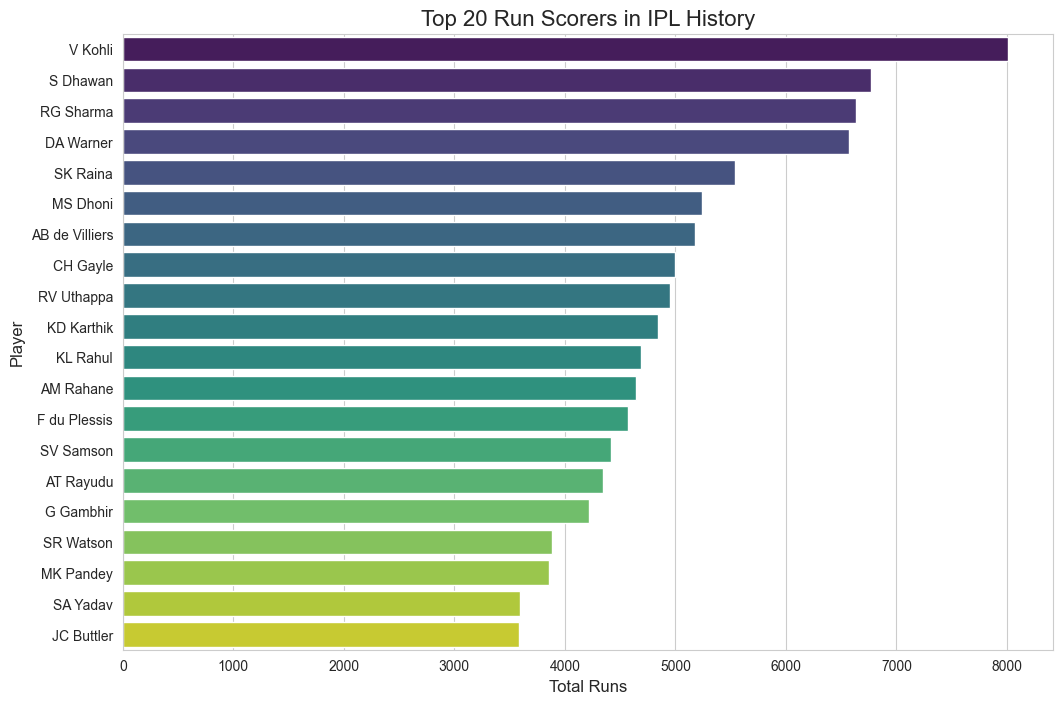

In [31]:
# Group by batter, sum their runs, sort in descending order, and get the top 20
top_scorers = df.groupby('batter')['batsman_runs'].sum().sort_values(ascending=False).head(20)

# Display the resulting Series
print(top_scorers)
# Create the bar plot
plt.figure(figsize=(12, 8))
sns.barplot(x=top_scorers.values, y=top_scorers.index, palette='viridis')

# Add titles and labels for clarity
plt.title('Top 20 Run Scorers in IPL History', fontsize=16)
plt.xlabel('Total Runs', fontsize=12)
plt.ylabel('Player', fontsize=12)

# Display the plot
plt.show()

In [32]:
# Filter for deliveries where batsman scored 4 runs, then count them per player
fours_df = df[df['batsman_runs'] == 4]
top_4_hitters = fours_df.groupby('batter')['batsman_runs'].count().sort_values(ascending=False).head(15)

# Filter for deliveries where batsman scored 6 runs, then count them per player
sixes_df = df[df['batsman_runs'] == 6]
top_6_hitters = sixes_df.groupby('batter')['batsman_runs'].count().sort_values(ascending=False).head(15)

# Display the results
print("--- Top 15 Players with Most 4s ---")
print(top_4_hitters)
print("\n--- Top 15 Players with Most 6s ---")
print(top_6_hitters)

--- Top 15 Players with Most 4s ---
batter
S Dhawan          768
V Kohli           708
DA Warner         663
RG Sharma         599
SK Raina          506
G Gambhir         492
RV Uthappa        481
AM Rahane         479
KD Karthik        466
F du Plessis      422
AB de Villiers    414
CH Gayle          408
KL Rahul          400
SA Yadav          385
SR Watson         377
Name: batsman_runs, dtype: int64

--- Top 15 Players with Most 6s ---
batter
CH Gayle          359
RG Sharma         281
V Kohli           273
AB de Villiers    253
MS Dhoni          252
DA Warner         236
KA Pollard        224
AD Russell        209
SV Samson         206
SK Raina          204
SR Watson         190
KL Rahul          187
RV Uthappa        182
AT Rayudu         173
F du Plessis      166
Name: batsman_runs, dtype: int64


C:\Users\amogh\AppData\Local\Temp\ipykernel_9500\1775010180.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_4_hitters.values, y=top_4_hitters.index, palette='plasma')


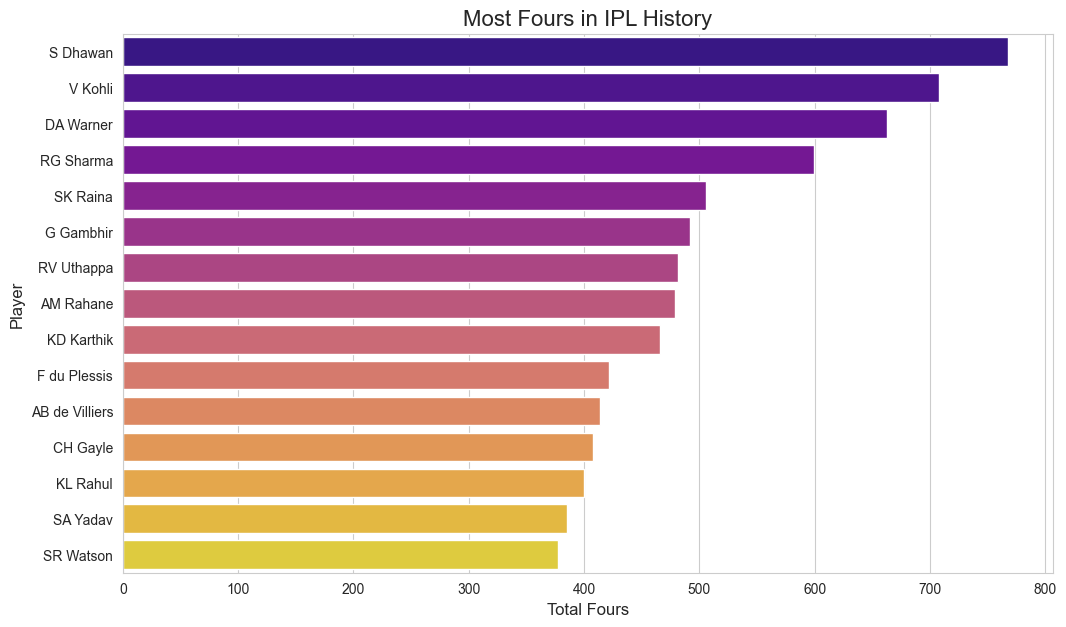

In [34]:
# Create the bar plot for most 4s
plt.figure(figsize=(12, 7))
sns.barplot(x=top_4_hitters.values, y=top_4_hitters.index, palette='plasma')

# Add titles and labels
plt.title('Most Fours in IPL History', fontsize=16)
plt.xlabel('Total Fours', fontsize=12)
plt.ylabel('Player', fontsize=12)

# Display the plot
plt.show()

C:\Users\amogh\AppData\Local\Temp\ipykernel_9500\1640178604.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_6_hitters.values, y=top_6_hitters.index, palette='magma')


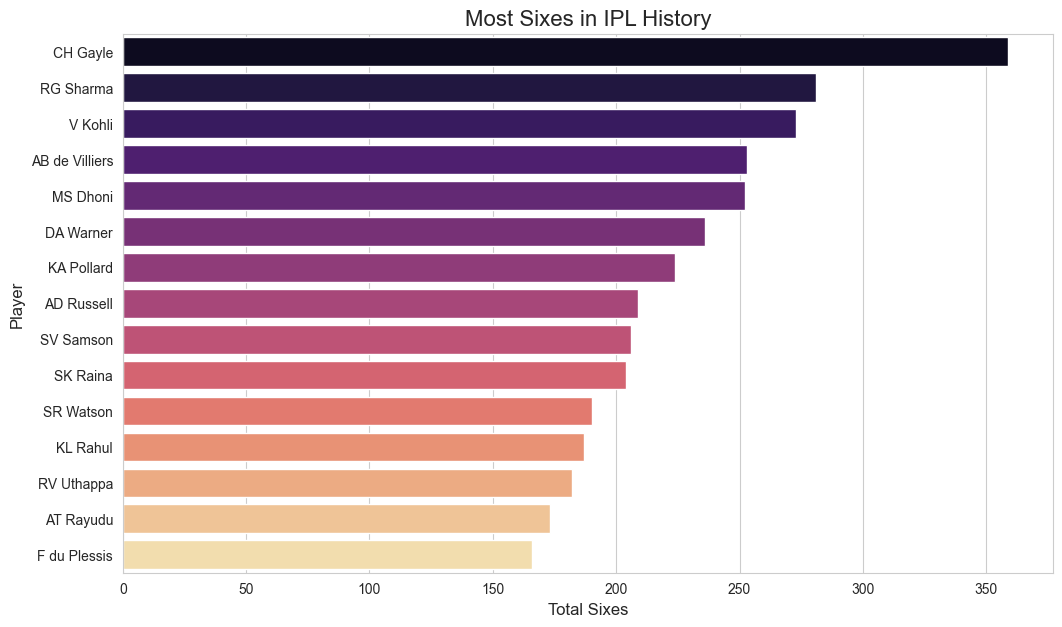

In [35]:
# Create the bar plot for most 6s
plt.figure(figsize=(12, 7))
sns.barplot(x=top_6_hitters.values, y=top_6_hitters.index, palette='magma')

# Add titles and labels
plt.title('Most Sixes in IPL History', fontsize=16)
plt.xlabel('Total Sixes', fontsize=12)
plt.ylabel('Player', fontsize=12)

# Display the plot
plt.show()

In [42]:
# Filter for scores between 50 and 99 to get the 50s
fifties = match_scores[(match_scores['batsman_runs'] >= 50) & (match_scores['batsman_runs'] < 100)]
top_50_scorers = fifties['batter'].value_counts().head(15)

# Filter for scores of 100 or more to get the 100s
hundreds = match_scores[match_scores['batsman_runs'] >= 100]
top_100_scorers = hundreds['batter'].value_counts().head(15)

# Display the results
print("--- Top 15 Players with Most 50s ---")
print(top_50_scorers)
print("\n--- Top 15 Players with Most 100s ---")
print(top_100_scorers)

--- Top 15 Players with Most 50s ---
batter
DA Warner         62
V Kohli           56
S Dhawan          51
RG Sharma         43
AB de Villiers    41
SK Raina          39
KL Rahul          37
F du Plessis      37
G Gambhir         36
CH Gayle          32
AM Rahane         30
RV Uthappa        27
SV Samson         25
MS Dhoni          24
SA Yadav          24
Name: count, dtype: int64

--- Top 15 Players with Most 100s ---
batter
V Kohli           8
JC Buttler        7
CH Gayle          6
DA Warner         4
SR Watson         4
KL Rahul          4
Shubman Gill      4
AB de Villiers    3
SV Samson         3
V Sehwag          2
AM Rahane         2
M Vijay           2
RD Gaikwad        2
Q de Kock         2
JM Bairstow       2
Name: count, dtype: int64


C:\Users\amogh\AppData\Local\Temp\ipykernel_9500\23122387.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_50_scorers.values, y=top_50_scorers.index, palette='coolwarm')


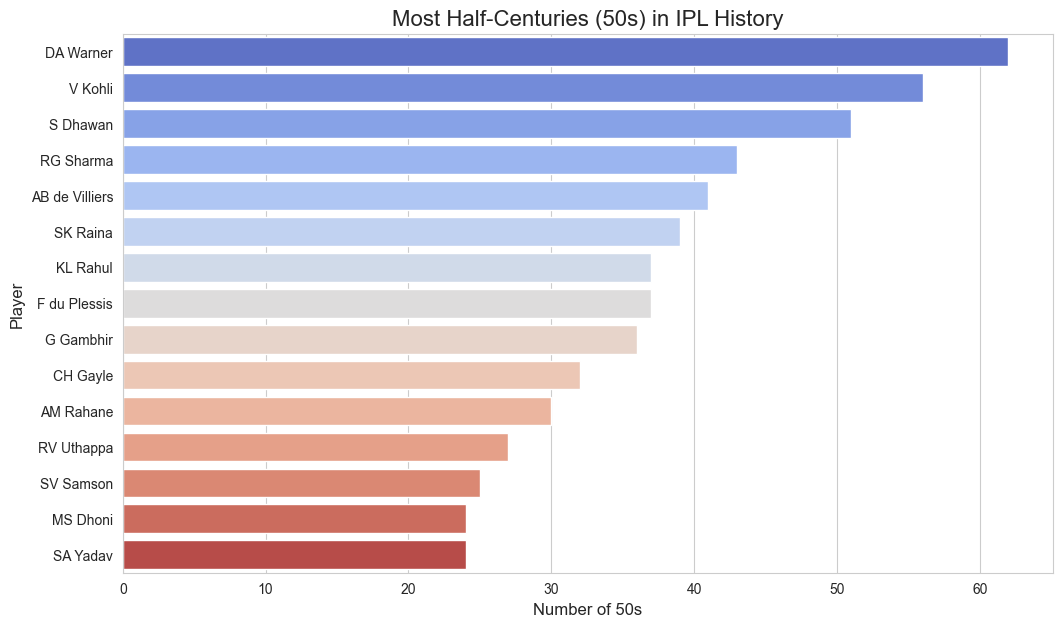

In [43]:
# Create the bar plot for most 50s
plt.figure(figsize=(12, 7))
sns.barplot(x=top_50_scorers.values, y=top_50_scorers.index, palette='coolwarm')

# Add titles and labels
plt.title('Most Half-Centuries (50s) in IPL History', fontsize=16)
plt.xlabel('Number of 50s', fontsize=12)
plt.ylabel('Player', fontsize=12)

# Display the plot
plt.show()

C:\Users\amogh\AppData\Local\Temp\ipykernel_9500\3222243057.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_100_scorers.values, y=top_100_scorers.index, palette='rocket')


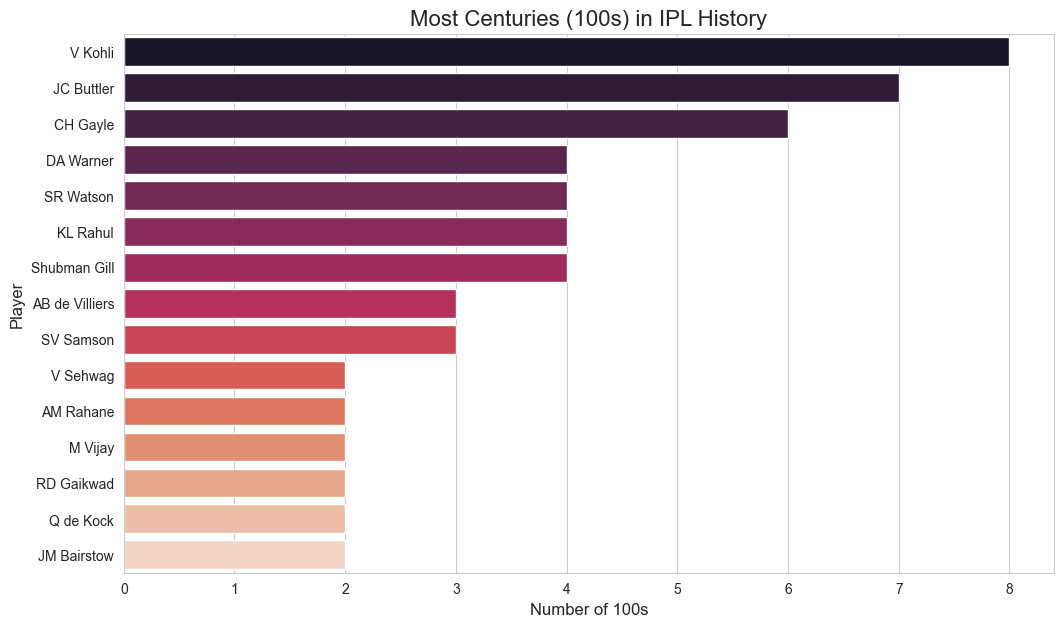

In [44]:
# Create the bar plot for most 100s
plt.figure(figsize=(12, 7))
sns.barplot(x=top_100_scorers.values, y=top_100_scorers.index, palette='rocket')

# Add titles and labels
plt.title('Most Centuries (100s) in IPL History', fontsize=16)
plt.xlabel('Number of 100s', fontsize=12)
plt.ylabel('Player', fontsize=12)

# Display the plot
plt.show()

In [45]:
# Calculate total runs for each batsman
runs = df.groupby('batter')['batsman_runs'].sum()

# Calculate total balls faced by each batsman (excluding wides)
# Wides are not counted as a legal delivery for the batsman.
balls_faced = df[df['extras_type'] != 'wides'].groupby('batter')['ball'].count()

# Create a new DataFrame with the calculated runs and balls
strike_rate_df = pd.DataFrame({'runs': runs, 'balls': balls_faced})

print("Calculated runs and balls faced for each player.")
display(strike_rate_df.head())

Calculated runs and balls faced for each player.


,runs,balls
batter,,
A Ashish Reddy,280,193
A Badoni,634,473
A Chandila,4,7
A Chopra,53,71
A Choudhary,25,20


In [46]:
# Calculate the strike rate
strike_rate_df['strike_rate'] = (strike_rate_df['runs'] / strike_rate_df['balls']) * 100

# Filter for players who have faced at least 500 balls for a meaningful comparison
min_balls_faced = 500
meaningful_sr = strike_rate_df[strike_rate_df['balls'] >= min_balls_faced].sort_values(by='strike_rate', ascending=False).head(15)

# Display the top 15
print(f"--- Top 15 Batsmen by Strike Rate (min. {min_balls_faced} balls) ---")
display(meaningful_sr)

--- Top 15 Batsmen by Strike Rate (min. 500 balls) ---


,runs,balls,strike_rate
batter,,,
AD Russell,2488,1423,174.841883
H Klaasen,993,590,168.305085
SP Narine,1534,925,165.837838
LS Livingstone,939,578,162.456747
N Pooran,1769,1092,161.996337
RM Patidar,799,503,158.846918
GJ Maxwell,2772,1769,156.698700
V Sehwag,2728,1755,155.441595
Abhishek Sharma,1377,887,155.242390


C:\Users\amogh\AppData\Local\Temp\ipykernel_9500\4218916708.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=meaningful_sr['strike_rate'], y=meaningful_sr.index, palette='inferno')


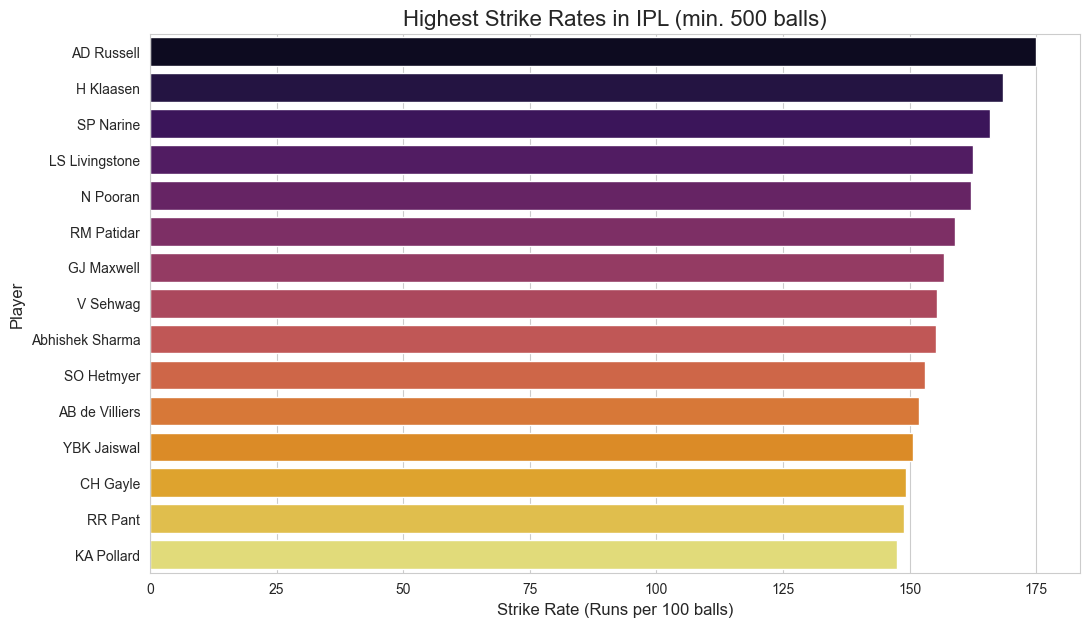

In [47]:
# Create the bar plot for top strike rates
plt.figure(figsize=(12, 7))
sns.barplot(x=meaningful_sr['strike_rate'], y=meaningful_sr.index, palette='inferno')

# Add titles and labels
plt.title(f'Highest Strike Rates in IPL (min. {min_balls_faced} balls)', fontsize=16)
plt.xlabel('Strike Rate (Runs per 100 balls)', fontsize=12)
plt.ylabel('Player', fontsize=12)

# Display the plot
plt.show()

In [48]:
# Create a new column 'partnership' by combining batter and non_striker names in a sorted tuple
df['partnership'] = df.apply(lambda row: tuple(sorted((row['batter'], row['non_striker']))), axis=1)

# Display the new column alongside the originals to verify
print("Created a standardized 'partnership' column.")
display(df[['batter', 'non_striker', 'partnership']].head())

Created a standardized 'partnership' column.


,batter,non_striker,partnership
0,SC Ganguly,BB McCullum,"(BB McCullum, SC Ganguly)"
1,BB McCullum,SC Ganguly,"(BB McCullum, SC Ganguly)"
2,BB McCullum,SC Ganguly,"(BB McCullum, SC Ganguly)"
3,BB McCullum,SC Ganguly,"(BB McCullum, SC Ganguly)"
4,BB McCullum,SC Ganguly,"(BB McCullum, SC Ganguly)"


In [49]:
# Group by the 'partnership' column, sum the total runs, and get the top 15
partnership_runs = df.groupby('partnership')['total_runs'].sum().sort_values(ascending=False).head(15)

# Display the result
print("--- Top 15 Partnerships by Runs Scored ---")
print(partnership_runs)

--- Top 15 Partnerships by Runs Scored ---
partnership
(AB de Villiers, V Kohli)    3134
(CH Gayle, V Kohli)          2802
(DA Warner, S Dhawan)        2357
(F du Plessis, V Kohli)      2032
(G Gambhir, RV Uthappa)      1906
(Ishan Kishan, RG Sharma)    1868
(KL Rahul, MA Agarwal)       1731
(JC Buttler, SV Samson)      1637
(CH Gayle, KL Rahul)         1633
(MS Dhoni, RA Jadeja)        1578
(MS Dhoni, SK Raina)         1482
(PP Shaw, S Dhawan)          1461
(DA Warner, JM Bairstow)     1401
(RR Pant, SS Iyer)           1368
(M Vijay, MEK Hussey)        1367
Name: total_runs, dtype: int64


C:\Users\amogh\AppData\Local\Temp\ipykernel_9500\3501227847.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=partnership_runs.values, y=partnership_runs.index, palette='YlGnBu_r')


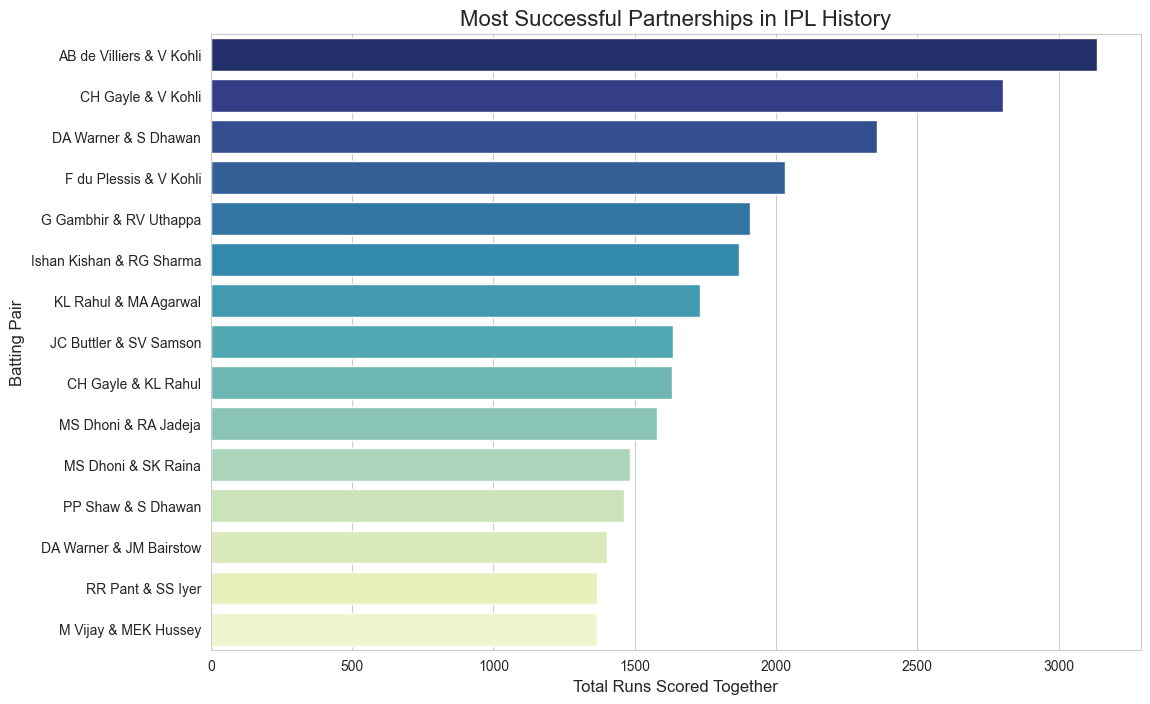

In [50]:
# The index is a tuple of names; we'll convert it to a more readable string format
partnership_runs.index = partnership_runs.index.map(lambda x: f"{x[0]} & {x[1]}")

# Create the bar plot
plt.figure(figsize=(12, 8))
sns.barplot(x=partnership_runs.values, y=partnership_runs.index, palette='YlGnBu_r')

# Add titles and labels
plt.title('Most Successful Partnerships in IPL History', fontsize=16)
plt.xlabel('Total Runs Scored Together', fontsize=12)
plt.ylabel('Batting Pair', fontsize=12)

# Display the plot
plt.show()

In [51]:
# Group by batter and phase to get total runs
runs_per_phase = df.groupby(['batter', 'phase'])['batsman_runs'].sum()

# Group by batter and phase to get balls faced (excluding wides)
balls_per_phase = df[df['extras_type'] != 'wides'].groupby(['batter', 'phase'])['ball'].count()

# Combine them into a new DataFrame
phase_stats_df = pd.DataFrame({
    'runs': runs_per_phase,
    'balls': balls_per_phase
}).reset_index()

print("Calculated runs and balls faced for each player in each phase.")
display(phase_stats_df.head())

Calculated runs and balls faced for each player in each phase.


,batter,phase,runs,balls
0,A Ashish Reddy,Death,192,127
1,A Ashish Reddy,Middle,83,60
2,A Ashish Reddy,Powerplay,5,6
3,A Badoni,Death,332,194
4,A Badoni,Middle,284,242


In [52]:
# Calculate strike rate for each phase
phase_stats_df['strike_rate'] = (phase_stats_df['runs'] / phase_stats_df['balls']) * 100

# Get the list of the top 20 overall run-scorers
top_scorers_list = df.groupby('batter')['batsman_runs'].sum().nlargest(20).index

# Filter our phase stats to only include these top players
top_players_phase_stats = phase_stats_df[phase_stats_df['batter'].isin(top_scorers_list)]

print("Filtered phase stats for the top 20 overall run-scorers.")
display(top_players_phase_stats.head())

Filtered phase stats for the top 20 overall run-scorers.


,batter,phase,runs,balls,strike_rate
65,AB de Villiers,Death,1421,611,232.569558
66,AB de Villiers,Middle,3019,2186,138.106130
67,AB de Villiers,Powerplay,741,614,120.684039
113,AM Rahane,Death,386,236,163.559322
114,AM Rahane,Middle,1937,1568,123.533163


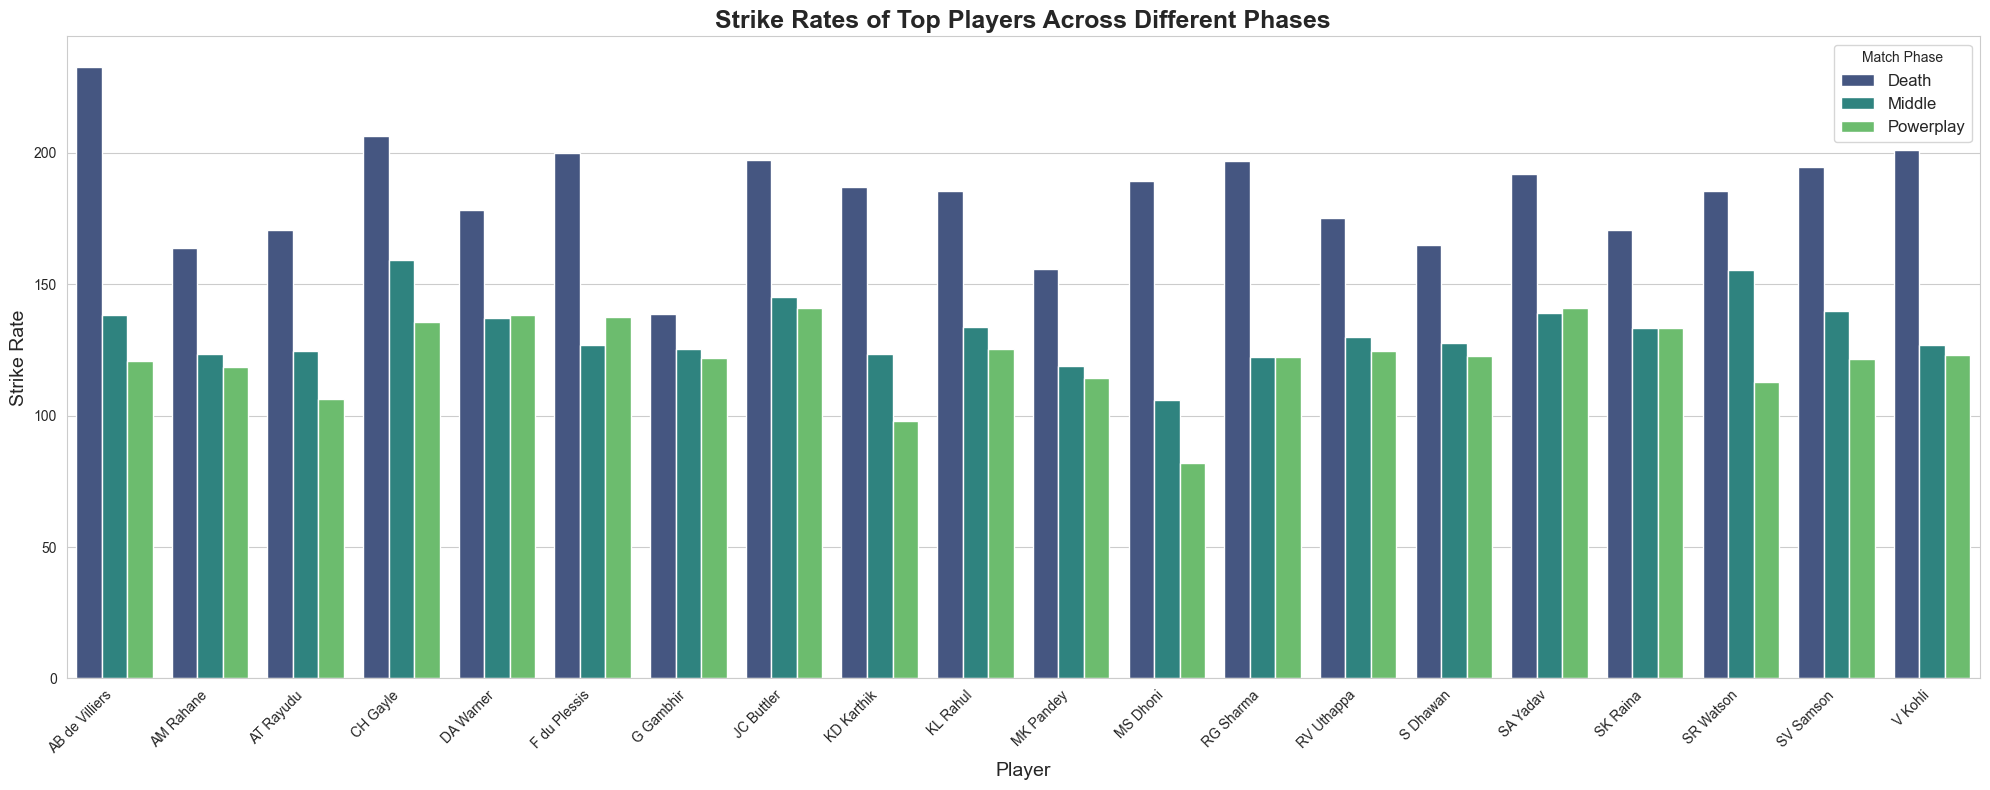

In [53]:
# Create the grouped bar plot
plt.figure(figsize=(20, 8))
sns.barplot(data=top_players_phase_stats, x='batter', y='strike_rate', hue='phase', palette='viridis')

# Improve the plot's readability
plt.title('Strike Rates of Top Players Across Different Phases', fontsize=18, fontweight='bold')
plt.xlabel('Player', fontsize=14)
plt.ylabel('Strike Rate', fontsize=14)
plt.xticks(rotation=45, ha='right') # Rotate player names for better visibility
plt.legend(title='Match Phase', fontsize=12)
plt.tight_layout() # Adjust layout to make sure everything fits

# Display the plot
plt.show()

BOWLING PHASE

C:\Users\amogh\AppData\Local\Temp\ipykernel_9500\484552625.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_wicket_takers.values, y=top_wicket_takers.index, palette='cubehelix')


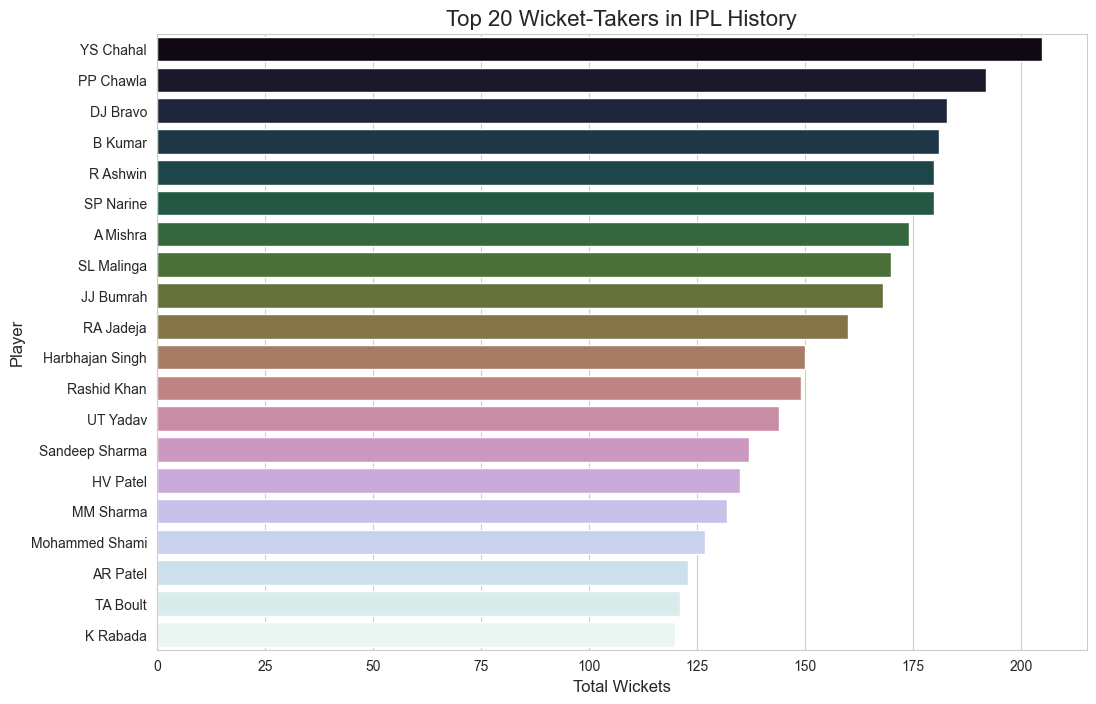

In [55]:
# Create the bar plot
plt.figure(figsize=(12, 8))
sns.barplot(x=top_wicket_takers.values, y=top_wicket_takers.index, palette='cubehelix')

# Add titles and labels for clarity
plt.title('Top 20 Wicket-Takers in IPL History', fontsize=16)
plt.xlabel('Total Wickets', fontsize=12)
plt.ylabel('Player', fontsize=12)

# Display the plot
plt.show()

In [56]:
# A dot ball is any delivery where the total runs scored is 0.
dot_balls_df = df[df['total_runs'] == 0]

# Group by the 'bowler' and count the number of dot balls
top_dot_ball_bowlers = dot_balls_df.groupby('bowler')['ball'].count().sort_values(ascending=False).head(20)

# Display the result
print("--- Top 20 Bowlers by Dot Balls Delivered ---")
print(top_dot_ball_bowlers)

--- Top 20 Bowlers by Dot Balls Delivered ---
bowler
B Kumar            1632
SP Narine          1569
R Ashwin           1552
PP Chawla          1325
Harbhajan Singh    1263
JJ Bumrah          1228
RA Jadeja          1216
YS Chahal          1194
UT Yadav           1186
A Mishra           1185
SL Malinga         1144
Sandeep Sharma     1122
P Kumar            1075
Rashid Khan        1060
AR Patel           1021
DW Steyn           1019
DJ Bravo            998
TA Boult            986
Mohammed Shami      984
I Sharma            969
Name: ball, dtype: int64


C:\Users\amogh\AppData\Local\Temp\ipykernel_9500\1046146228.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_dot_ball_bowlers.values, y=top_dot_ball_bowlers.index, palette='crest_r')


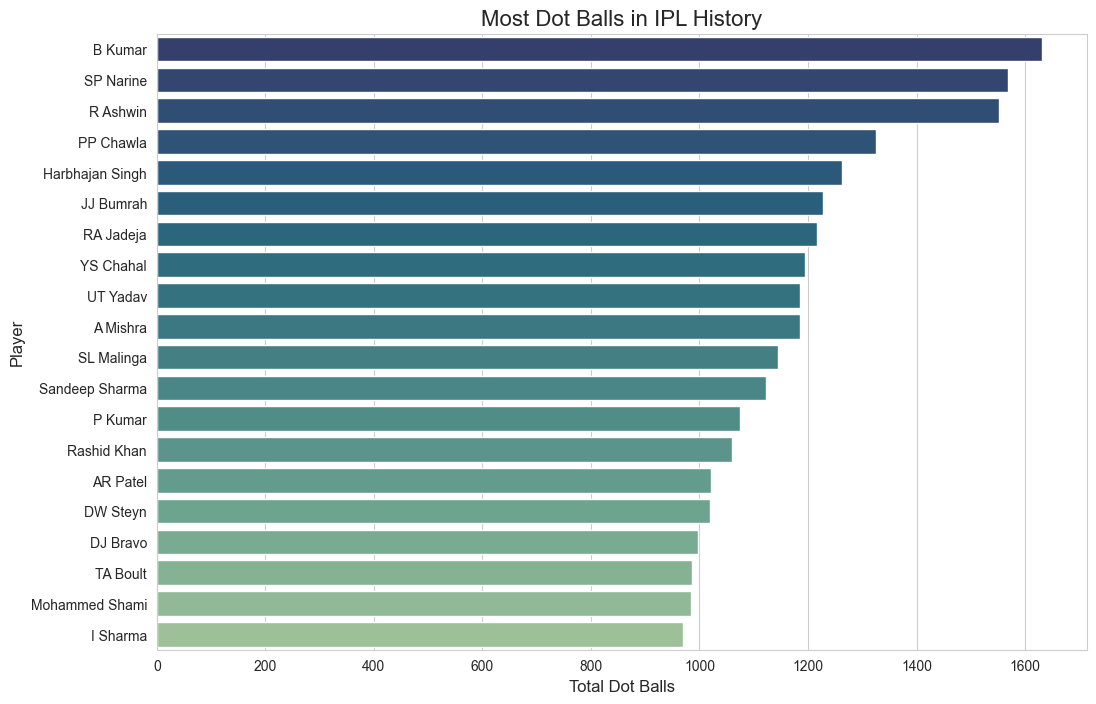

In [57]:
# Create the bar plot
plt.figure(figsize=(12, 8))
sns.barplot(x=top_dot_ball_bowlers.values, y=top_dot_ball_bowlers.index, palette='crest_r')

# Add titles and labels for clarity
plt.title('Most Dot Balls in IPL History', fontsize=16)
plt.xlabel('Total Dot Balls', fontsize=12)
plt.ylabel('Player', fontsize=12)

# Display the plot
plt.show()

In [59]:
# We reuse 'wickets_df' which only contains valid bowler wickets
wickets_per_match = wickets_df.groupby(['match_id', 'bowler'])['is_wicket'].count().reset_index()

# Rename the column for clarity
wickets_per_match.rename(columns={'is_wicket': 'wickets_in_match'}, inplace=True)

print("Calculated wickets per bowler for each match:")
display(wickets_per_match.head())
# Count instances where a bowler took 3 or more wickets
three_wickets = wickets_per_match[wickets_per_match['wickets_in_match'] >= 3]
top_3_wicket_hauls = three_wickets['bowler'].value_counts().head(15)

# Count instances where a bowler took 5 or more wickets
five_wickets = wickets_per_match[wickets_per_match['wickets_in_match'] >= 5]
top_5_wicket_hauls = five_wickets['bowler'].value_counts().head(15)

# Display the results
print("--- Top 15 Bowlers by 3+ Wicket Hauls ---")
print(top_3_wicket_hauls)
print("\n--- Top 15 Bowlers by 5+ Wicket Hauls ---")
print(top_5_wicket_hauls)

Calculated wickets per bowler for each match:


,match_id,bowler,wickets_in_match
0,335982,AA Noffke,1
1,335982,AB Agarkar,3
2,335982,AB Dinda,2
3,335982,I Sharma,1
4,335982,JH Kallis,1


--- Top 15 Bowlers by 3+ Wicket Hauls ---
bowler
JJ Bumrah      24
YS Chahal      20
SL Malinga     19
RA Jadeja      17
A Mishra       17
UT Yadav       16
Rashid Khan    16
MM Sharma      16
DJ Bravo       16
B Kumar        15
SP Narine      15
PP Chawla      15
HV Patel       15
A Nehra        14
AD Russell     13
Name: count, dtype: int64

--- Top 15 Bowlers by 5+ Wicket Hauls ---
bowler
JJ Bumrah          3
JD Unadkat         2
JP Faulkner        2
B Kumar            2
SL Malinga         1
L Balaji           1
A Mishra           1
Sohail Tanvir      1
MM Patel           1
I Sharma           1
Harbhajan Singh    1
RA Jadeja          1
SP Narine          1
AD Mascarenhas     1
A Zampa            1
Name: count, dtype: int64


C:\Users\amogh\AppData\Local\Temp\ipykernel_9500\2863746192.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_3_wicket_hauls.values, y=top_3_wicket_hauls.index, palette='viridis_r')


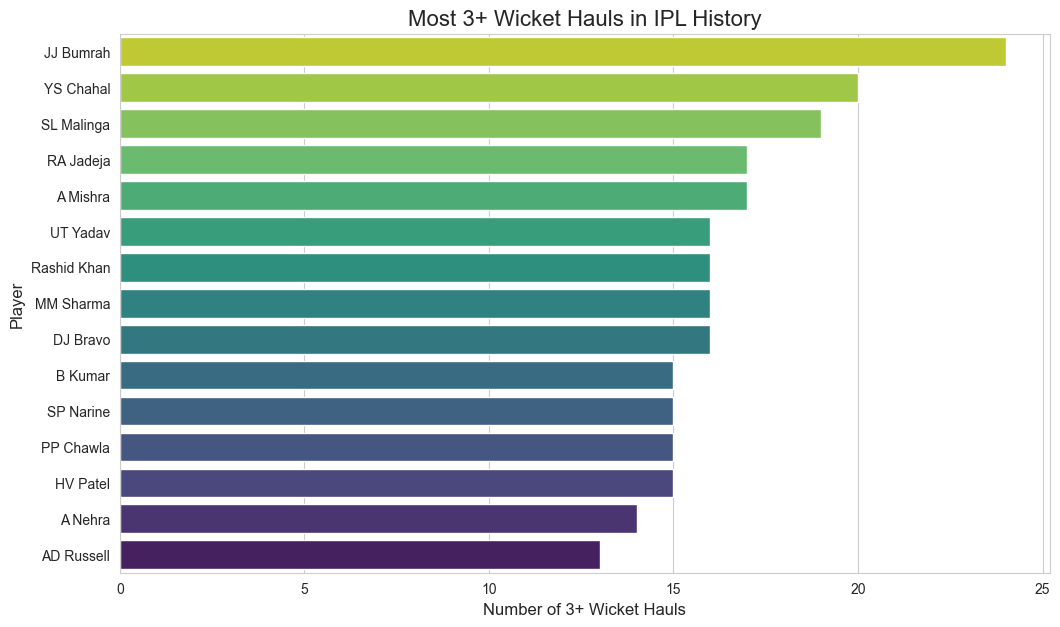

C:\Users\amogh\AppData\Local\Temp\ipykernel_9500\2863746192.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_5_wicket_hauls.values, y=top_5_wicket_hauls.index, palette='plasma_r')


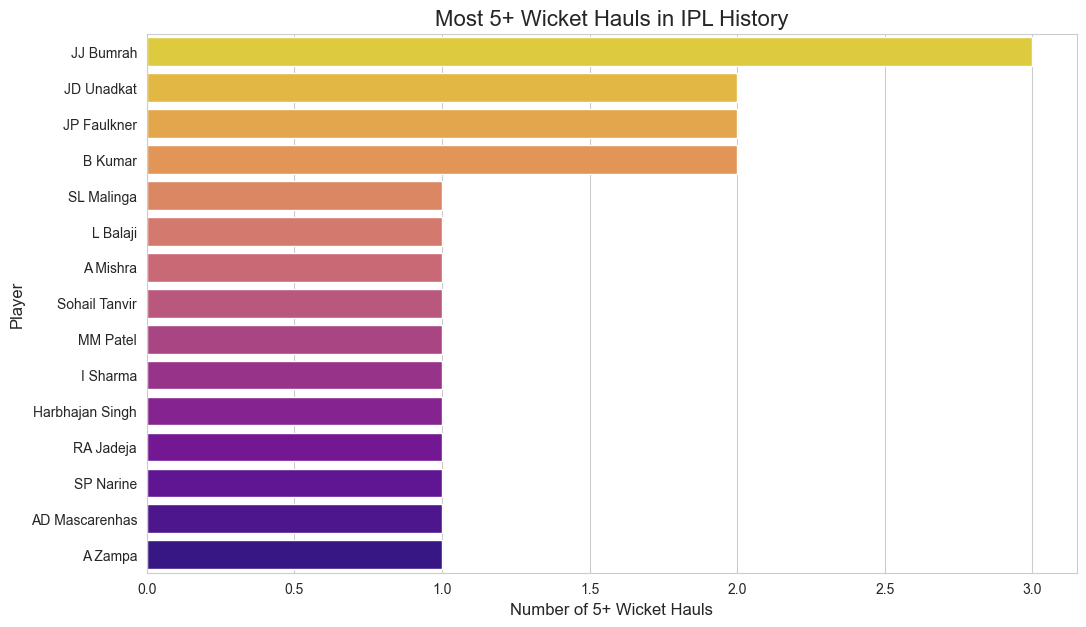

In [60]:
# Create the bar plot for most 3+ wicket hauls
plt.figure(figsize=(12, 7))
sns.barplot(x=top_3_wicket_hauls.values, y=top_3_wicket_hauls.index, palette='viridis_r')

# Add titles and labels
plt.title('Most 3+ Wicket Hauls in IPL History', fontsize=16)
plt.xlabel('Number of 3+ Wicket Hauls', fontsize=12)
plt.ylabel('Player', fontsize=12)

# Display the plot
plt.show()
# Create the bar plot for most 5+ wicket hauls
plt.figure(figsize=(12, 7))
sns.barplot(x=top_5_wicket_hauls.values, y=top_5_wicket_hauls.index, palette='plasma_r')

# Add titles and labels
plt.title('Most 5+ Wicket Hauls in IPL History', fontsize=16)
plt.xlabel('Number of 5+ Wicket Hauls', fontsize=12)
plt.ylabel('Player', fontsize=12)

# Display the plot
plt.show()

In [61]:
# Calculate total runs conceded by each bowler
runs_conceded = df.groupby('bowler')['total_runs'].sum()

# Calculate total legal balls bowled (excluding wides and no-balls)
legal_balls = df[~df['extras_type'].isin(['wides', 'noballs'])]
balls_bowled = legal_balls.groupby('bowler')['ball'].count()

# Combine the two series into a DataFrame
economy_df = pd.DataFrame({'runs_conceded': runs_conceded, 'balls_bowled': balls_bowled})

print("Calculated runs conceded and legal balls bowled for each player.")
display(economy_df.head())

Calculated runs conceded and legal balls bowled for each player.


,runs_conceded,balls_bowled
bowler,,
A Ashish Reddy,400,262
A Badoni,37,25
A Chandila,245,234
A Choudhary,144,101
A Dananjaya,47,24


In [62]:
# Drop any bowlers with no legal deliveries bowled (an edge case)
economy_df.dropna(inplace=True)

# Calculate economy rate: (Total Runs / Total Balls) * 6
economy_df['economy_rate'] = (economy_df['runs_conceded'] / economy_df['balls_bowled']) * 6

# Filter for bowlers who have bowled at least 500 legal balls
min_balls_bowled = 500
meaningful_economy = economy_df[economy_df['balls_bowled'] >= min_balls_bowled].sort_values(by='economy_rate', ascending=True).head(15)

# Display the top 15 most economical bowlers
print(f"--- Top 15 Bowlers by Economy Rate (min. {min_balls_bowled} balls) ---")
display(meaningful_economy)


--- Top 15 Bowlers by Economy Rate (min. 500 balls) ---


,runs_conceded,balls_bowled,economy_rate
bowler,,,
A Kumble,1089,965,6.770984
SP Narine,4672,4081,6.868905
DL Vettori,894,777,6.903475
M Muralitharan,1765,1528,6.930628
Rashid Khan,3340,2872,6.977716
J Botha,818,694,7.072046
DW Steyn,2583,2182,7.102658
R Sharma,1100,928,7.112069
MM Ali,900,758,7.124011


C:\Users\amogh\AppData\Local\Temp\ipykernel_9500\1134102399.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=meaningful_economy['economy_rate'], y=meaningful_economy.index, palette='magma_r')


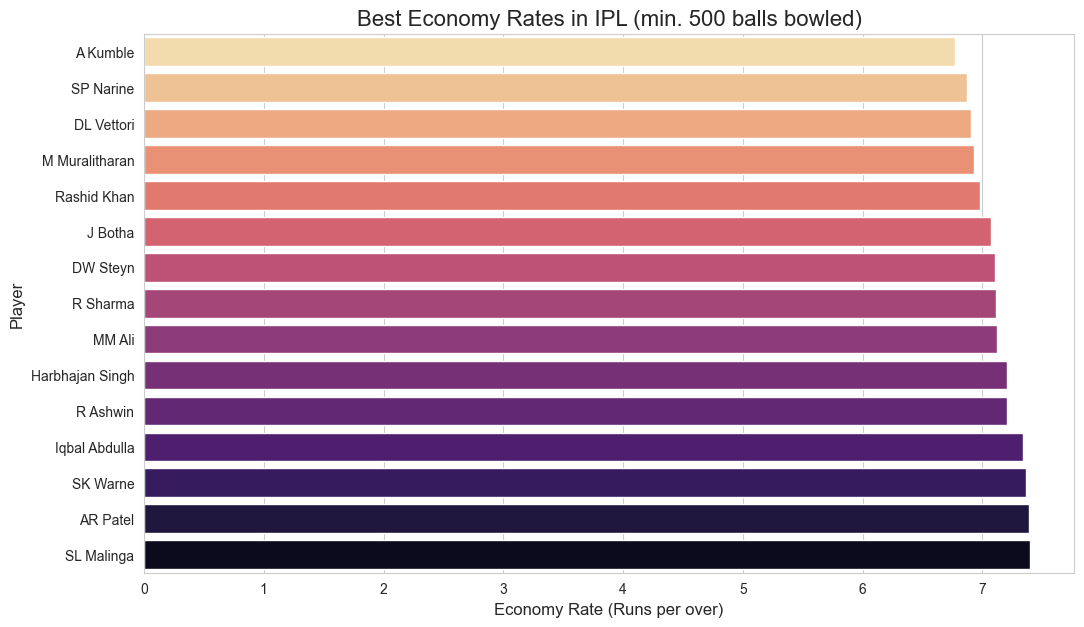

In [63]:
# Create the bar plot for the best economy rates
plt.figure(figsize=(12, 7))
sns.barplot(x=meaningful_economy['economy_rate'], y=meaningful_economy.index, palette='magma_r')

# Add titles and labels
plt.title(f'Best Economy Rates in IPL (min. {min_balls_bowled} balls bowled)', fontsize=16)
plt.xlabel('Economy Rate (Runs per over)', fontsize=12)
plt.ylabel('Player', fontsize=12)

# Display the plot
plt.show()

HEAD2HEAD

In [70]:
# --- CHOOSE YOUR BATSMAN ---
batsman_to_analyze = 'V Kohli'

nemesis_df = wickets_df[wickets_df['batter'] == batsman_to_analyze]

nemesis_bowlers = nemesis_df['bowler'].value_counts().head(10)

# Display the result
print(f"--- Top Bowlers Who Have Dismissed {batsman_to_analyze} the Most ---")
print(nemesis_bowlers)

--- Top Bowlers Who Have Dismissed V Kohli the Most ---
bowler
Sandeep Sharma    7
A Nehra           6
JJ Bumrah         5
Mohammed Shami    5
SP Narine         4
B Kumar           4
MJ McClenaghan    4
DS Kulkarni       4
L Balaji          3
IK Pathan         3
Name: count, dtype: int64


C:\Users\amogh\AppData\Local\Temp\ipykernel_9500\578276487.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=nemesis_bowlers.values, y=nemesis_bowlers.index, palette='cool_r')


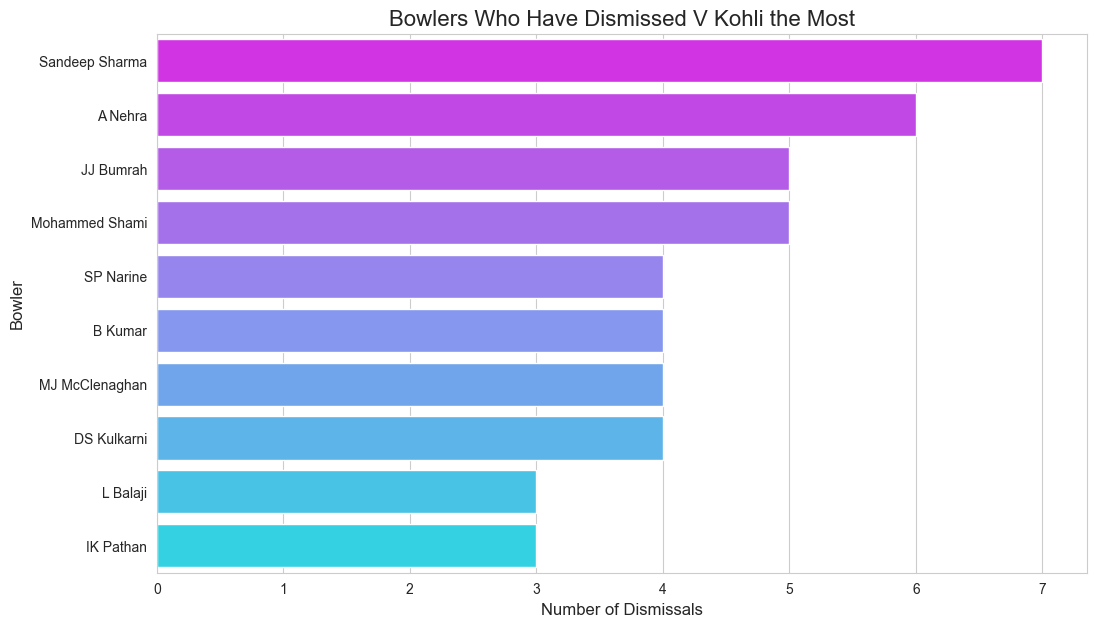

In [71]:
# Check if the series is not empty to avoid errors
if not nemesis_bowlers.empty:
    # Create the bar plot
    plt.figure(figsize=(12, 7))
    sns.barplot(x=nemesis_bowlers.values, y=nemesis_bowlers.index, palette='cool_r')

    # Add titles and labels
    plt.title(f'Bowlers Who Have Dismissed {batsman_to_analyze} the Most', fontsize=16)
    plt.xlabel(f'Number of Dismissals', fontsize=12)
    plt.ylabel('Bowler', fontsize=12)

    # Display the plot
    plt.show()
else:
    print(f"No dismissal data found for {batsman_to_analyze}.")

 Team & Match Dynamics Analysis

In [73]:
# Group by the batting team and sum the total runs scored
team_runs = df.groupby('batting_team')['total_runs'].sum().sort_values(ascending=False)

# Display the result
print("--- Total Runs Scored by Each Team ---")
print(team_runs)

--- Total Runs Scored by Each Team ---
batting_team
Mumbai Indians                 42176
Royal Challengers Bengaluru    40622
Sunrisers Hyderabad            40534
Punjab Kings                   39600
Kolkata Knight Riders          39331
Delhi Capitals                 39196
Chennai Super Kings            38629
Rajasthan Royals               34747
Gujarat Titans                  7757
Lucknow Super Giants            7510
Pune Warriors                   6358
Gujarat Lions                   4862
Rising Pune Supergiants         4533
Kochi Tuskers Kerala            1901
Name: total_runs, dtype: int64


C:\Users\amogh\AppData\Local\Temp\ipykernel_9500\2001683186.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=team_runs.values, y=team_runs.index, palette='rocket')


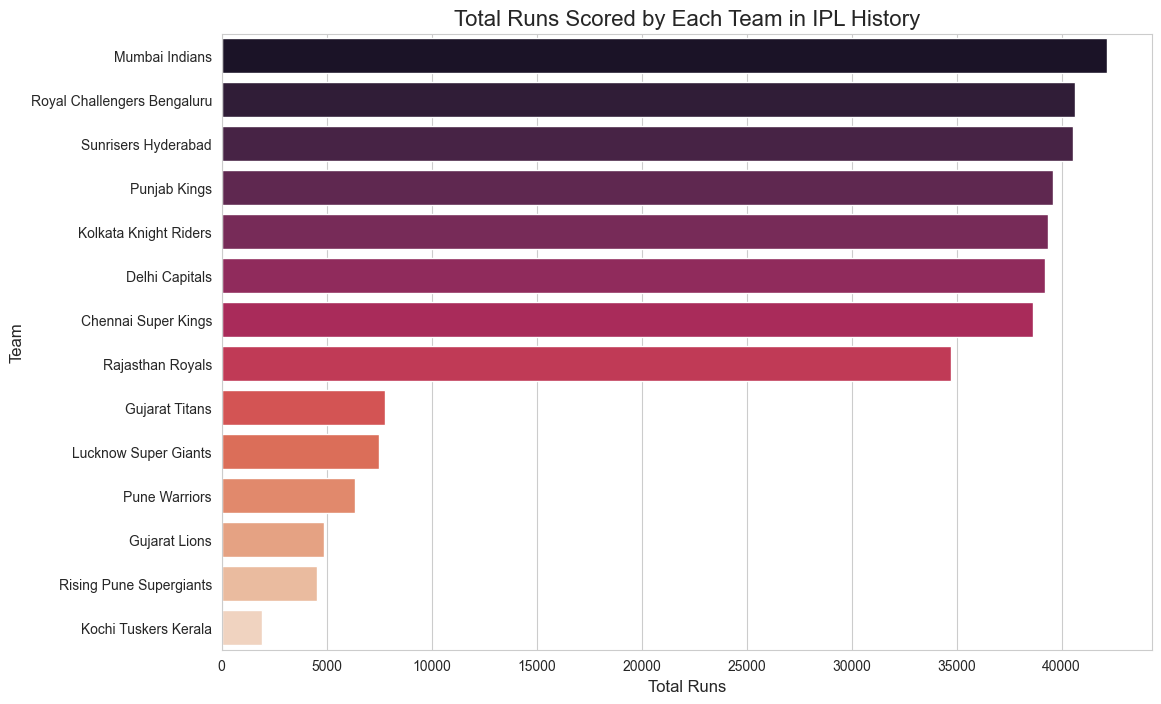

In [74]:
# Create the bar plot
plt.figure(figsize=(12, 8))
sns.barplot(x=team_runs.values, y=team_runs.index, palette='rocket')

# Add titles and labels
plt.title('Total Runs Scored by Each Team in IPL History', fontsize=16)
plt.xlabel('Total Runs', fontsize=12)
plt.ylabel('Team', fontsize=12)

# Display the plot
plt.show()

In [76]:
# Calculate the total runs scored in each over across all matches
total_runs_per_over = df.groupby('over')['total_runs'].sum()

num_innings = df[df['inning'] == 1]['match_id'].nunique()

# Calculate the average runs scored per over across all innings
avg_runs_in_over = (total_runs_per_over / num_innings)

# Display the result
print("--- Average Runs Scored in Each Over ---")
print(avg_runs_in_over)

--- Average Runs Scored in Each Over ---
over
0     12.466667
1     14.760731
2     16.342466
3     16.817352
4     16.954338
5     16.920548
6     13.551598
7     14.594521
8     15.195434
9     14.934247
10    15.323288
11    15.594521
12    15.712329
13    16.104110
14    16.574429
15    16.869406
16    17.362557
17    17.862100
18    17.421005
19    16.223744
Name: total_runs, dtype: float64


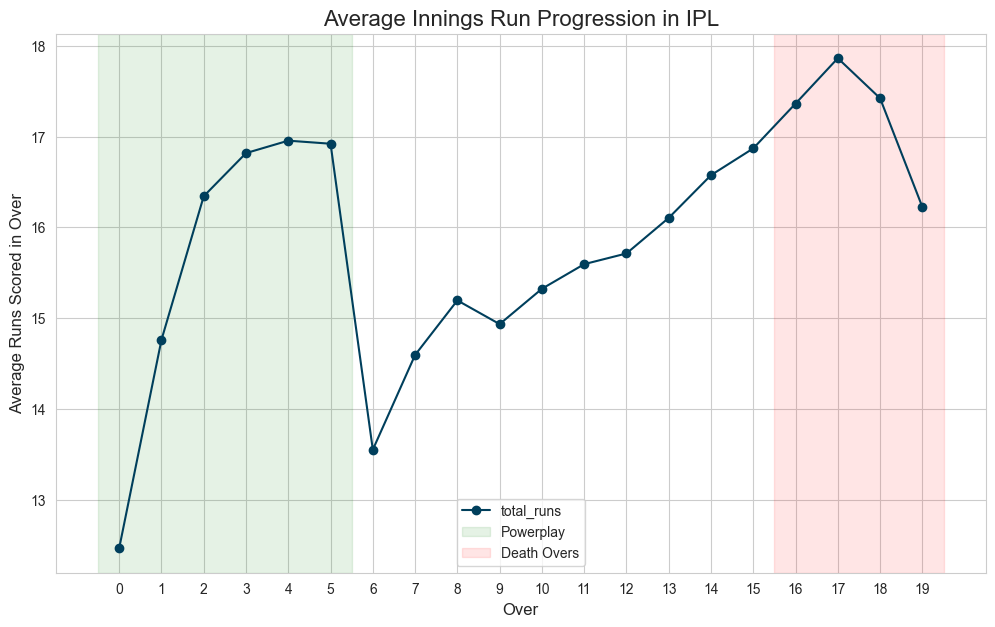

In [77]:
# Create the line plot
plt.figure(figsize=(12, 7))
avg_runs_in_over.plot(kind='line', marker='o', color='#003f5c')

# Add titles and labels
plt.title('Average Innings Run Progression in IPL', fontsize=16)
plt.xlabel('Over', fontsize=12)
plt.ylabel('Average Runs Scored in Over', fontsize=12)
plt.xticks(np.arange(0, 20, 1)) # Ensure all overs are marked on the x-axis
plt.grid(True)
plt.axvspan(-0.5, 5.5, color='green', alpha=0.1, label='Powerplay')
plt.axvspan(15.5, 19.5, color='red', alpha=0.1, label='Death Overs')
plt.legend()

# Display the plot
plt.show()

In [78]:
# Filter the DataFrame to include only the first innings of each match
first_innings_df = df[df['inning'] == 1]

# Group by the match_id and sum the total runs to get the final score
first_innings_scores = first_innings_df.groupby('match_id')['total_runs'].sum()

# Display the first few calculated scores
print("--- First Innings Scores for Each Match ---")
display(first_innings_scores.head())

--- First Innings Scores for Each Match ---


match_id
335982    222
335983    240
335984    129
335985    165
335986    110
Name: total_runs, dtype: int64

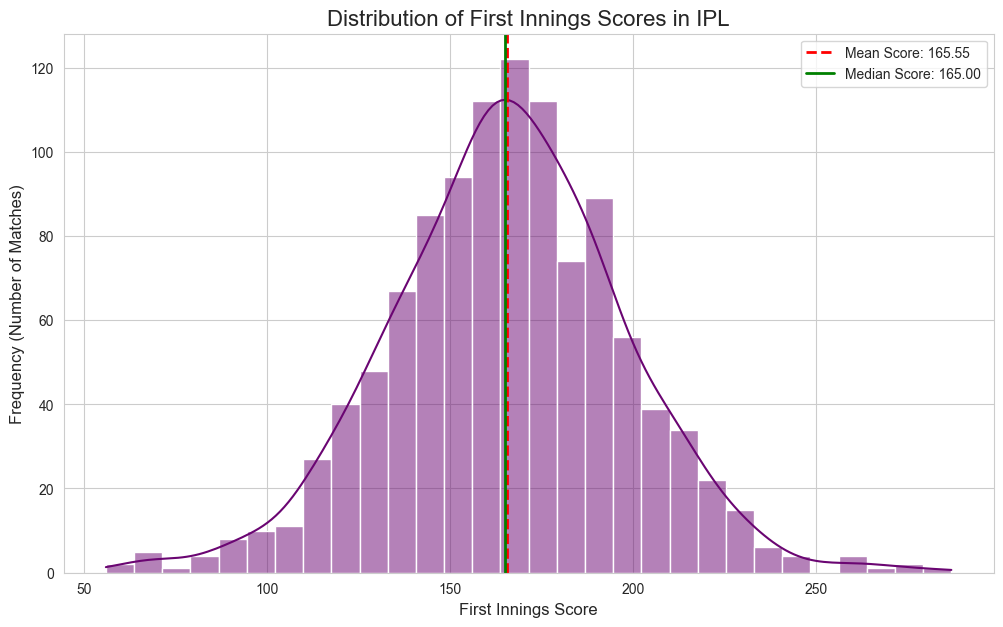

In [79]:
# Create the histogram
plt.figure(figsize=(12, 7))
sns.histplot(first_innings_scores, bins=30, kde=True, color='#6a0572') # Histogram with a density curve

# Add vertical lines for the mean and median scores
plt.axvline(first_innings_scores.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean Score: {first_innings_scores.mean():.2f}')
plt.axvline(first_innings_scores.median(), color='green', linestyle='-', linewidth=2, label=f'Median Score: {first_innings_scores.median():.2f}')

# Add titles and labels
plt.title('Distribution of First Innings Scores in IPL', fontsize=16)
plt.xlabel('First Innings Score', fontsize=12)
plt.ylabel('Frequency (Number of Matches)', fontsize=12)
plt.legend()

# Display the plot
plt.show()